# Psychometric curves - Tutorial

# Introduction

In this tutorial, we consider a toy example from a sensory discrimination task. The idea is to introduce the concepts of a psychometric curve and likelihood estimation before we apply them to a more complex dataset.

Our behavioral dataset corresponds to a standard two-alternative forced-choice task, where on each trial subjects have to report the direction of motion of a stimulus with a binary response (left or right). The stimulus strength (or stimulus evidence) is varied across trials: negative values correspond to evidence for leftward motion, positive values to evidence for rightward motion. 

We want to describe how the subject's response (left or right) depends on the evidence strength.

# Summary statistics: the psychometric curve
A natural way of summarizing the subject's responses in sensory tasks with binary choices is to extract the **psychometric curve**, corresponding to the proportion of rightward choices as a function of stimulus evidence. We plot the psychometric curve below. See how it captures the relationship between stimulus and choice.

In [1]:
# first, import relevant packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import scipy.optimize as optimize
import ipywidgets as widgets       # interactive display

In [2]:
# load the data (change to local path if you're working locally)
df_exp = pd.read_csv("https://raw.githubusercontent.com/wimmerlab/MBC_data_analysis/main/A3_PsychometricCurves/dataset_tutorial.csv",sep=',')
df_exp.head()

,stimulus,response
0,3.0,1
1,2.0,1
2,1.0,1
3,3.0,1
4,1.0,1


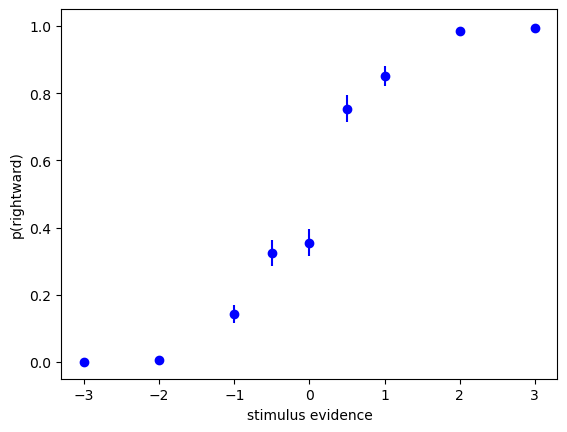

In [3]:
#define function to plot psychometric curve
def plot_data_psychometric(df):
    """
    Plots the psychometric curve (mean and s.e.m. of choices for each stimulus value).
    Args:
       df (dataframe): dataset.
    """
    # plot psychometric curve
    df.groupby('stimulus').response.agg(('mean','sem')).plot(yerr='sem', fmt = 'bo', ax=plt.gca(), legend=False);

    plt.xlabel('stimulus evidence');
    plt.ylabel('p(rightward)');
    plt.ylim(-0.05, 1.05);

# apply the function on the experimental dataframe
plot_data_psychometric(df_exp)

# Fit a psychometric function


## 1. Logistic function
The plot above summarizes the dependence of perceptual choices for a few different values of the stimulus evidence. We would like to formalize this into a simple model that captures the statistical relationship between the stimulus strength and the choice. More specifically, the model will characterize the probability of a rightward choice $p(r=1|s)$ as a function of the stimulus evidence $s$. We cannot use a simple linear relationship $p(r=1|s) = w_0 + w_1 s$ because this would predict that (for any $w_1 \neq 0$) as $s$ goes to infinity (either $+ \infty$ or $-\infty$), $p(r=1|s)$ would also go to $+\infty$ or $-\infty$, i.e. it would leave the range of valid probabilities. But $p(r=1|s)$ is a probability so it is **bounded between 0 and 1**. So we need to introduce a non-linearity that maps all continuous values onto values in the range [0, 1]. This is obtained by using a sigmoidal function. A classical example of a sigmoidal function is the logistic function $\sigma$:
<br> 
$\sigma(x) = \frac{1}{1+ e^{-x}}$
<br>
You don't need to memorize the formula, but here is what the function looks like:


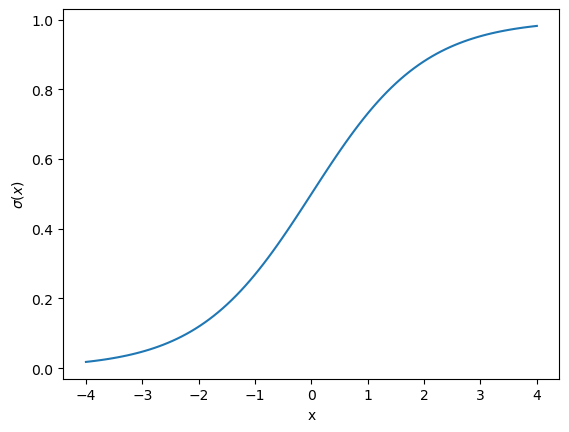

In [4]:
# let's define the logistic function
def logistic(x):
    y = 1 / (1 + np.exp(-x))
    return y    

# to plot a function, we first make an array with many values (here 100) 
# paving all the space in a certain range (here, from -4 to 4)
X = np.linspace(-4,4,100)

# then we compute the value of the function at each of these values
Y = logistic(X)

# and then we just plot the curve joining the dots: easy!
plt.plot(X,Y,'-');

# (and don't forget the labels)
plt.xlabel('x');
plt.ylabel(r'$\sigma(x)$');

See, a sigmoidal function with values bounded between 0 and 1, just as we wanted! <br>
Evaluate the function at different values to check that you understand how it works:

In [5]:
print(logistic(0))

0.5


Now, we will plug the linear predictor $w_0 + w_1 s$ into this sigmoidal function, which gives us the formula: <br>
$p(r=1|s) = \sigma(w_0 + w_1 s) = \frac{1}{1+ e^{-(w_0 + w_1 s)}}$

This is our psychometric model. It gives a probability of response = 1 (rightward choice) as a function of stimulus strength $s$. It has two parameters $w_0$ and $w_1$, similarly to simple linear regression. $w_0$ is the **bias**: it shifts the curve horizontally. The curve crosses $p=0.5$ at $s = -w_0/w_1$, so $w_0>0$ means a bias towards rightward choices. $w_1$ is the **slope** (or sensitivity): the larger $w_1$, the more steeply the curve rises, i.e. the more the choices depend on the stimulus. You will explore their role with the widget below.


In [6]:
# define probability of rightward choices according to logistic model
def psychometric_model(s, w0, w1):
    """
    Computes the probability of rightward choices according to the logistic model 
    Args:
        s (array): sensory evidence, for each trial
        w0 (scalar): bias
        w1 (scalar): slope
    Returns:
        array: probability of rightward choice, for each trial
    """
    
    # probability of rightward choice
    p = logistic(w0 + w1 * s)
    
    return p

# Plot psychometric function at continuous values, for given model 
def plot_model(w0, w1):

    # define 100 stimulus values linearly spaced between -3 and 3
    s_linspace = np.linspace(-3,3,100)
    
    p = psychometric_model(s_linspace, w0, w1)
    
    # plot fitted psychometric functions
    plt.plot(s_linspace, p, 'b')
    
    plt.xlabel('stimulus evidence')
    plt.ylabel('p(rightward)')
    plt.ylim(-0.05, 1.05)

## 2. Naive fitting

A naive fitting procedure is to manually adjust the parameters in the model to try to visually match the experimental and theoretical psychometric curves. Here we just adjust the parameters by hand so that the predicted value captures the summary statistics qualitatively.

**Now use the widget below to adjust parameters to yield the best possible fit between experimental and theoretical psychometric curves. Is the fit good enough?**

In [7]:
#@title

#@markdown Make sure you execute this cell to enable the widget!

@widgets.interact(
    w0 = widgets.FloatSlider(0.0, min=-2.0, max=2.0), # default, min and max values for bias w0
    w1 = widgets.FloatSlider(0.5, min=0.0, max=4.0)) # default, min and max values for slope w1

def plot_data_estimate(w0, w1):
   
    # plot model predictions
    plot_model(w0, w1)

    # plot psychometric curve on top
    plot_data_psychometric(df_exp)
    
    plt.show(); # needed for Colab
    

interactive(children=(FloatSlider(value=0.0, description='w0', max=2.0, min=-2.0), FloatSlider(value=0.5, desc…

## 3. Likelihood function
Now we will use a more principled approach to parameter estimation by looking for the set of parameters that maximize a given metric, namely the **log-likelihood** (LLH) of the data. The likelihood is the probability of the observed data given the model and a set of parameters, $P(\text{data}|w_0,w_1)$. The likelihood function is a function, defined for a given model and dataset, that takes the **parameters as input**. Assuming that trials are independent, the likelihood of the whole dataset is the product of the likelihoods of the individual trials, so the log-likelihood is the **sum** of the log-likelihoods of the individual trials.
Complete the following function to compute the log-likelihood of the model for a given set of parameters.

In [8]:
def LogLikelihood(df, w0, w1):
    """
    Computes the log-likelihood of model with certain parameter set
    Args:
        df (dataframe): dataset
        w0 (scalar): bias
        w1 (scalar): slope
    Returns:
        scalar: log-likelihood of model
    """
    # p of rightward choice for each trial in dataset, according to the model
    p = psychometric_model(df.stimulus, w0, w1)
    
    # likelihood for each trial (=p if choice is rightward, 1-p otherwise)
    lh = np.where(df.response==1, p, 1-p)
    
    # avoid log(0) (when p is numerically 0 or 1)
    lh = np.clip(lh, np.finfo(float).eps, 1)
    
    # log-likelihood for whole dataset (sum of log-likelihood of individual trials)
    LLH = np.sum(np.log(lh))
    
    return LLH

Compute the log-likelihood at the parameter values you obtained by naive fitting (use your own values from the widget).

In [9]:
llh_manual = LogLikelihood(df_exp, w0=-0.3, w1=1.5)
print(llh_manual)

-422.3436498953181


## 4. Maximum likelihood estimation

Now that we have a function of parameters that defines a metric for how well the model accounts for the data, we can identify the maximum-likelihood parameters by using an **optimization algorithm** over the LLH function. Because most optimization tools are defined for minimization rather than maximization, we will actually minimize the negative log-likelihood (which is equivalent to maximizing the LLH).


In [10]:
# Define the objective function (to be minimized)
def neg_LLH(pp, df):
    """
    Computes the neg-LLH for the model.
    Args:
        - pp (list): set of parameters (w0, w1)
        - df (dataframe): dataset
    Returns:
        - scalar: negative LLH
    """
    return -LogLikelihood(df, pp[0], pp[1])

# Define the bounds for each variable
bounds = [(-10.0, 10.0), (0.001, 10)]  # w0 between -10 and +10; w1 between 0.001 and 10 (w1 > 0 forces a positive slope)

# Initial guess for parameter set
x0 = [0.75, 0.5]

# Perform the optimization with bounds
result = optimize.minimize(neg_LLH, x0=x0, args=(df_exp,), bounds=bounds)

# Retrieve the optimized parameters
(w0_hat, w1_hat) = result.x

# print
print("optimization successful:", result.success)
print("w0_hat =",w0_hat)
print("w1_hat =",w1_hat)
print("LLH =",LogLikelihood(df_exp,w0_hat,w1_hat))


optimization successful: True
w0_hat = -0.09906470532358067
w1_hat = 1.8989905532423281
LLH = -411.19480060768


**Now, let's plot the data again and plot the best fitting psychometric function (the maximum likelihood estimate).** Also mark the stimulus value where the fitted curve crosses $p=0.5$, i.e. $s=-\hat{w}_0/\hat{w}_1$.

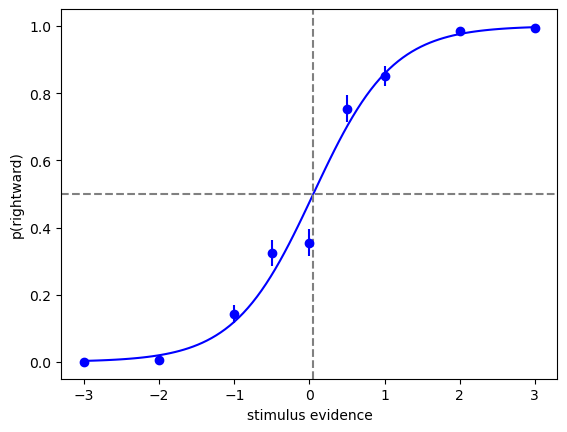

In [11]:
# plot the maximum likelihood fit and the data
plot_model(w0_hat, w1_hat)
plot_data_psychometric(df_exp)

# mark the point where the fitted curve crosses p=0.5
plt.axvline(-w0_hat/w1_hat, color='gray', linestyle='--');
plt.axhline(0.5, color='gray', linestyle='--');
plt.show();

Voilà! You can compare this fit to what you got above by adjusting the parameters by hand. Note that maximum likelihood estimation is a very general and powerful tool: we can apply it to all problems where we can compute the likelihood of the data given some model. For example, we could use a more complex psychometric function with more parameters (e.g. a lapse rate). Moreover, once fitted, the model can be used to make predictions for experimental conditions not seen in the dataset (e.g. the responses to stimulus values that were never presented).

## 5. Visualizing the likelihood function (optional)

To get a better intuition about the likelihood function and the optimization procedure, we will plot the value of the LLH as a function of both parameters, as a colored plot. We'll add the maximum likelihood parameters as a red dot on the LLH profile. Note that the LLH of the logistic model has a single peak (it is a concave function of $w_0$ and $w_1$), which is why the optimizer reliably finds the maximum, whatever the initial guess.


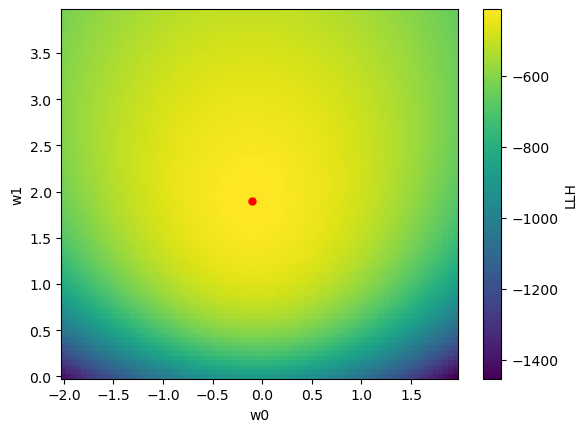

In [12]:
# define linearly spaced values of w0 and w1
w0_grid = np.arange(-2, 2, 0.05)
w1_grid = np.arange(0, 4.0, 0.05)

# compute all possible pairs of parameter values (defining a grid)
W0, W1 = np.meshgrid(w0_grid, w1_grid)

# compute LLH for each of these parameter sets
LLH = np.zeros(W0.shape)
for j in range(W0.shape[0]):
    for k in range(W0.shape[1]):
        LLH[j,k] = LogLikelihood(df_exp, w0=W0[j,k], w1=W1[j,k])

# define function to plot Log-Likelihood profile
def show_LL(LLH,w0,w1):
    im=plt.pcolormesh(w0, w1, LLH, shading='nearest');
    plt.ylabel('w1')
    plt.xlabel('w0')
    plt.colorbar(im, label='LLH')
    

# plot LLH profile
show_LL(LLH,w0_grid,w1_grid)

# add MLE parameters as red dot
plt.plot(w0_hat, w1_hat, marker='o', markersize=5, color='red');
